### Conexão com o Google Drive




In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

DRIVE_DIRECTORY = "IC"
DRIVE_DIRECTORY = os.path.join("/content/drive/MyDrive", DRIVE_DIRECTORY)
if not os.path.exists(DRIVE_DIRECTORY):
    os.makedirs(DRIVE_DIRECTORY)

### Importação das bibliotecas

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

### Leitura dos dados

In [4]:
dengue = pd.read_csv(os.path.join(DRIVE_DIRECTORY, 'dengue.csv'), sep=';', encoding='latin1')
clima = pd.read_csv(os.path.join(DRIVE_DIRECTORY, 'clima_inmet.csv'), sep=';', encoding='latin1')

In [5]:
dengue

,Semana epidem. 1.Sintomas(s),2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,1,-,7,1,2,-,3,4,3,8,29,1
1,2,-,16,-,-,1,2,2,1,8,24,5
2,3,1,24,2,-,-,2,11,5,7,32,3
3,4,-,58,2,-,2,-,19,9,8,55,4
4,5,3,70,1,-,1,11,29,10,17,57,9
5,6,2,73,8,-,2,12,49,12,10,100,2
6,7,1,89,3,-,1,17,40,25,30,106,6
7,8,1,89,1,-,-,26,48,23,14,135,5
8,9,-,78,2,1,1,15,87,20,30,233,5
9,10,4,134,7,-,1,26,98,28,36,256,7


In [6]:
clima

,Data Medicao,"PRECIPITACAO TOTAL, DIARIO (AUT)(mm)","TEMPERATURA MAXIMA, DIARIA","TEMPERATURA MEDIA, DIARIA","TEMPERATURA MINIMA, DIARIA","UMIDADE RELATIVA DO AR, MEDIA DIARIA (AUT)"
0,01/01/2014,NaN,33,"26,9","21,7","75,5"
1,02/01/2014,NaN,"32,9","25,9","21,3","77,5"
2,03/01/2014,NaN,"36,3","28,7","23,2","66,8"
3,04/01/2014,NaN,"36,2","28,2",23,"61,3"
4,05/01/2014,NaN,35,"27,1","20,4","60,7"
...,...,...,...,...,...,...
4013,27/12/2024,NaN,NaN,NaN,NaN,NaN
4014,28/12/2024,NaN,NaN,NaN,NaN,NaN
4015,29/12/2024,NaN,NaN,NaN,NaN,NaN
4016,30/12/2024,NaN,NaN,NaN,NaN,NaN


### Substituindo os valores de "-" para 0.
A substituição dos valores é para informar que os campos que contém "-" não possuí casos de dengue.


In [7]:
dengue = dengue.replace("-", 0)

In [8]:
dengue

,Semana epidem. 1.Sintomas(s),2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,1,0,7,1,2,0,3,4,3,8,29,1
1,2,0,16,0,0,1,2,2,1,8,24,5
2,3,1,24,2,0,0,2,11,5,7,32,3
3,4,0,58,2,0,2,0,19,9,8,55,4
4,5,3,70,1,0,1,11,29,10,17,57,9
5,6,2,73,8,0,2,12,49,12,10,100,2
6,7,1,89,3,0,1,17,40,25,30,106,6
7,8,1,89,1,0,0,26,48,23,14,135,5
8,9,0,78,2,1,1,15,87,20,30,233,5
9,10,4,134,7,0,1,26,98,28,36,256,7


In [9]:
dengue_anos = dengue[["2014", "2015", "2016", "2017", "2018", "2019", "2020", "2021", "2022", "2023", "2024"]]
dengue_anos

,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,0,7,1,2,0,3,4,3,8,29,1
1,0,16,0,0,1,2,2,1,8,24,5
2,1,24,2,0,0,2,11,5,7,32,3
3,0,58,2,0,2,0,19,9,8,55,4
4,3,70,1,0,1,11,29,10,17,57,9
5,2,73,8,0,2,12,49,12,10,100,2
6,1,89,3,0,1,17,40,25,30,106,6
7,1,89,1,0,0,26,48,23,14,135,5
8,0,78,2,1,1,15,87,20,30,233,5
9,4,134,7,0,1,26,98,28,36,256,7


### Visualização em gráfico do número de casos de dengue ao decorrer dos anos

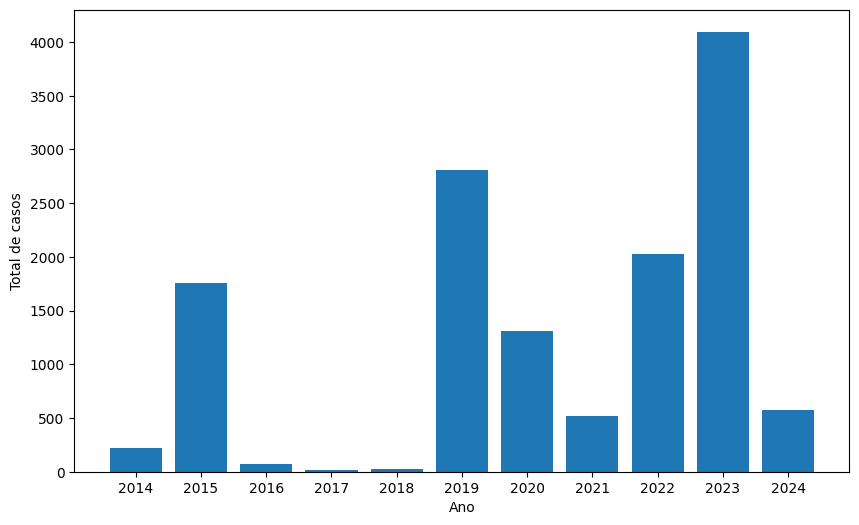

In [10]:
anos = [str(a) for a in range(2014, 2025)]
totais = dengue[anos].replace('-', 0).astype(int).sum()

plt.figure(figsize=(10,6))
plt.bar(totais.index, totais.values)
plt.xlabel('Ano')
plt.ylabel('Total de casos')
plt.show()

### Renomeando os nomes das colunas do Dataframe clima

In [11]:
clima = clima.rename(columns={
    'Data Medicao' : 'data',
    'PRECIPITACAO TOTAL, DIARIO (AUT)(mm)' : 'precipitacao_mm',
    'TEMPERATURA MAXIMA, DIARIA ': 'temp_max_c',
    'TEMPERATURA MEDIA, DIARIA ': 'temp_media_c',
    'TEMPERATURA MINIMA, DIARIA': 'temp_min_c',
    'UMIDADE RELATIVA DO AR, MEDIA DIARIA (AUT)': 'umidade_media_percent'
})

In [12]:
clima.head()

,data,precipitacao_mm,temp_max_c,temp_media_c,temp_min_c,umidade_media_percent
0,01/01/2014,NaN,33,"26,9","21,7","75,5"
1,02/01/2014,NaN,"32,9","25,9","21,3","77,5"
2,03/01/2014,NaN,"36,3","28,7","23,2","66,8"
3,04/01/2014,NaN,"36,2","28,2",23,"61,3"
4,05/01/2014,NaN,35,"27,1","20,4","60,7"


### Convertendo a coluna de data

In [13]:
clima['data'] = pd.to_datetime(clima['data'], format='%d/%m/%Y')

In [14]:
clima.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4018 entries, 0 to 4017
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   data                   4018 non-null   datetime64[ns]
 1   precipitacao_mm        3191 non-null   object        
 2   temp_max_c             3659 non-null   object        
 3   temp_media_c           3638 non-null   object        
 4   temp_min_c             3673 non-null   object        
 5   umidade_media_percent  3691 non-null   object        
dtypes: datetime64[ns](1), object(5)
memory usage: 188.5+ KB


### Corrigindo valores numéricos

In [15]:
colunas_numericas = ['precipitacao_mm', 'temp_max_c', 'temp_media_c', 'temp_min_c', 'umidade_media_percent']

for col in colunas_numericas:
  clima[col] = clima[col].replace('null', np.nan)
  clima[col] = clima[col].str.replace(',','.').astype(float)


In [16]:
clima.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4018 entries, 0 to 4017
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   data                   4018 non-null   datetime64[ns]
 1   precipitacao_mm        3191 non-null   float64       
 2   temp_max_c             3659 non-null   float64       
 3   temp_media_c           3638 non-null   float64       
 4   temp_min_c             3673 non-null   float64       
 5   umidade_media_percent  3691 non-null   float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 188.5 KB


### Tratamento dos dados climáticos

In [17]:
print('contagem de valores nulos após o tratamento: ', clima.isnull().sum())

contagem de valores nulos após o tratamento:  data                       0
precipitacao_mm          827
temp_max_c               359
temp_media_c             380
temp_min_c               345
umidade_media_percent    327
dtype: int64


In [18]:
# Verificação de último dia com dados válidos
ultimo_indice_valido = clima['temp_media_c'].last_valid_index()
ultima_data_valida = clima.loc[ultimo_indice_valido, 'data']

print('Última data com medição de temperatura: ', ultima_data_valida.date())

Última data com medição de temperatura:  2024-10-16


In [19]:
# Quantidade de linhas antes
len(clima)

4018

In [20]:
# Cortando o dataframe
clima = clima[clima['data'] <= ultima_data_valida]

In [21]:
# Quantidade de linhas depois
len(clima)

3942

In [22]:
# Tratando nulos de precipitacao
clima ['precipitacao_mm'] = clima['precipitacao_mm'].fillna(0)

In [23]:
# Interpolação dados nulos
colunas_para_interpolar = ['temp_max_c', 'temp_media_c', 'temp_min_c', 'umidade_media_percent']
clima[colunas_para_interpolar] = clima[colunas_para_interpolar].interpolate(method='linear')

In [24]:
# Contagem de dados nulos
clima.isnull().sum()

,0
data,0
precipitacao_mm,0
temp_max_c,0
temp_media_c,0
temp_min_c,0
umidade_media_percent,0


In [25]:
# Últimas 10 linhas do dataframe
clima.tail(10)

,data,precipitacao_mm,temp_max_c,temp_media_c,temp_min_c,umidade_media_percent
3932,2024-10-07,0.0,38.0,27.8,18.0,31.6
3933,2024-10-08,0.0,41.4,29.4,19.2,33.8
3934,2024-10-09,0.0,34.2,26.4,21.3,45.6
3935,2024-10-10,0.0,25.1,21.8,19.1,77.4
3936,2024-10-11,0.0,30.6,23.5,19.6,77.1
3937,2024-10-12,0.0,30.9,24.5,19.7,64.7
3938,2024-10-13,0.0,35.4,26.5,19.5,48.1
3939,2024-10-14,0.0,36.2,26.7,19.2,49.8
3940,2024-10-15,0.0,34.3,26.3,19.1,52.0
3941,2024-10-16,0.0,36.1,27.4,21.4,53.8


In [26]:
# Primeiras 5 linhas
clima.head()

,data,precipitacao_mm,temp_max_c,temp_media_c,temp_min_c,umidade_media_percent
0,2014-01-01,0.0,33.0,26.9,21.7,75.5
1,2014-01-02,0.0,32.9,25.9,21.3,77.5
2,2014-01-03,0.0,36.3,28.7,23.2,66.8
3,2014-01-04,0.0,36.2,28.2,23.0,61.3
4,2014-01-05,0.0,35.0,27.1,20.4,60.7


In [27]:
dengue.head()

,Semana epidem. 1.Sintomas(s),2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,1,0,7,1,2,0,3,4,3,8,29,1
1,2,0,16,0,0,1,2,2,1,8,24,5
2,3,1,24,2,0,0,2,11,5,7,32,3
3,4,0,58,2,0,2,0,19,9,8,55,4
4,5,3,70,1,0,1,11,29,10,17,57,9


In [28]:
df_dengue_long = dengue.melt( # O "melt" joga as colunas de anos para dentro de uma única coluna 'Ano'
    id_vars=['Semana epidem. 1.Sintomas(s)'],
    var_name='Ano',
    value_name='Casos'
)

df_dengue_long

,Semana epidem. 1.Sintomas(s),Ano,Casos
0,1,2014,0
1,2,2014,0
2,3,2014,1
3,4,2014,0
4,5,2014,3
...,...,...,...
578,49,2024,31
579,50,2024,44
580,51,2024,37
581,52,2024,20


In [29]:
# Renomear para facilitar e garantir que são números inteiros
df_dengue_long = df_dengue_long.rename(columns={'Semana epidem. 1.Sintomas(s)': 'Semana'})
df_dengue_long['Ano'] = df_dengue_long['Ano'].astype(int)
df_dengue_long['Semana'] = df_dengue_long['Semana'].astype(int)

In [30]:
# Tratamento do Clima (Diário para Semanal)
# Extrair o Ano e a Semana da data
clima['data'] = pd.to_datetime(clima['data'])
clima['Ano'] = clima['data'].dt.isocalendar().year
clima['Semana'] = clima['data'].dt.isocalendar().week
clima

,data,precipitacao_mm,temp_max_c,temp_media_c,temp_min_c,umidade_media_percent,Ano,Semana
0,2014-01-01,0.0,33.0,26.9,21.7,75.5,2014,1
1,2014-01-02,0.0,32.9,25.9,21.3,77.5,2014,1
2,2014-01-03,0.0,36.3,28.7,23.2,66.8,2014,1
3,2014-01-04,0.0,36.2,28.2,23.0,61.3,2014,1
4,2014-01-05,0.0,35.0,27.1,20.4,60.7,2014,1
...,...,...,...,...,...,...,...,...
3937,2024-10-12,0.0,30.9,24.5,19.7,64.7,2024,41
3938,2024-10-13,0.0,35.4,26.5,19.5,48.1,2024,41
3939,2024-10-14,0.0,36.2,26.7,19.2,49.8,2024,42
3940,2024-10-15,0.0,34.3,26.3,19.1,52.0,2024,42


In [31]:
# Definir como agregar cada coluna
agg_dict = {
    'precipitacao_mm': 'sum', # Chuva se soma (acumulado da semana)
    'temp_max_c': 'mean', # Temperatura se faz média
    'temp_media_c': 'mean',
    'temp_min_c': 'mean',
    'umidade_media_percent': 'mean'
}

In [32]:
# Agrupar por Ano e Semana e aplicar as agregações
df_clima_semanal = clima.groupby(['Ano', 'Semana']).agg(agg_dict).reset_index()

In [33]:
# Unificação (Merge)
df_final = pd.merge(df_dengue_long, df_clima_semanal, on=['Ano', 'Semana'], how='inner')

In [34]:
# Ordenar cronologicamente
df_final = df_final.sort_values(by=['Ano', 'Semana'])

In [35]:
df_final.head()

,Semana,Ano,Casos,precipitacao_mm,temp_max_c,temp_media_c,temp_min_c,umidade_media_percent
0,1,2014,0,0.0,34.680000,27.360000,21.920000,68.360000
1,2,2014,0,0.0,33.914286,26.614286,21.557143,61.071429
2,3,2014,1,0.0,31.771429,25.300000,20.157143,68.228571
3,4,2014,0,0.0,34.142857,26.628571,21.757143,64.828571
4,5,2014,3,0.0,34.771429,27.314286,21.242857,53.500000


In [36]:
df_final

,Semana,Ano,Casos,precipitacao_mm,temp_max_c,temp_media_c,temp_min_c,umidade_media_percent
0,1,2014,0,0.0,34.680000,27.360000,21.920000,68.360000
1,2,2014,0,0.0,33.914286,26.614286,21.557143,61.071429
2,3,2014,1,0.0,31.771429,25.300000,20.157143,68.228571
3,4,2014,0,0.0,34.142857,26.628571,21.757143,64.828571
4,5,2014,3,0.0,34.771429,27.314286,21.242857,53.500000
...,...,...,...,...,...,...,...,...
559,38,2024,5,0.0,32.928571,24.571429,18.300000,53.928571
560,39,2024,9,0.0,37.528571,28.871429,21.514286,35.985714
561,40,2024,9,0.0,37.185714,27.757143,19.614286,39.685714
562,41,2024,8,0.0,33.657143,25.700000,19.485714,54.042857


In [37]:
import os

DRIVE_DIRECTORY = "/content/drive/MyDrive/IC"  # ajuste se o seu caminho for diferente

colunas_export = [
    "Ano",
    "Semana",
    "Casos",
    "precipitacao_mm",
    "temp_max_c",
    "temp_media_c",
    "temp_min_c",
    "umidade_media_percent",
]

# 'df_final' aqui e o DataFrame logo apos o merge (ainda sem sin/cos e sem lags)
caminho_saida = os.path.join(DRIVE_DIRECTORY, "historico_semanal.csv")
df_final[colunas_export].to_csv(caminho_saida, index=False)

print(f"Historico semanal exportado em: {caminho_saida}")
print(f"Total de semanas exportadas: {len(df_final)}")

Historico semanal exportado em: /content/drive/MyDrive/IC/historico_semanal.csv
Total de semanas exportadas: 564


O modelo não entende que a semana 52 é vizinha da semana 1. Por este motivo, é ideal usar novas colunas usando seno e cosseno.

In [38]:
# Cria duas novas colunas para representar a semana
df_final['semana_sin'] = np.sin(2 * np.pi * df_final['Semana'] / 52)
df_final['semana_cos'] = np.cos(2 * np.pi * df_final['Semana'] / 52)

In [39]:
df_final

,Semana,Ano,Casos,precipitacao_mm,temp_max_c,temp_media_c,temp_min_c,umidade_media_percent,semana_sin,semana_cos
0,1,2014,0,0.0,34.680000,27.360000,21.920000,68.360000,0.120537,9.927089e-01
1,2,2014,0,0.0,33.914286,26.614286,21.557143,61.071429,0.239316,9.709418e-01
2,3,2014,1,0.0,31.771429,25.300000,20.157143,68.228571,0.354605,9.350162e-01
3,4,2014,0,0.0,34.142857,26.628571,21.757143,64.828571,0.464723,8.854560e-01
4,5,2014,3,0.0,34.771429,27.314286,21.242857,53.500000,0.568065,8.229839e-01
...,...,...,...,...,...,...,...,...,...,...
559,38,2024,5,0.0,32.928571,24.571429,18.300000,53.928571,-0.992709,-1.205367e-01
560,39,2024,9,0.0,37.528571,28.871429,21.514286,35.985714,-1.000000,-1.836970e-16
561,40,2024,9,0.0,37.185714,27.757143,19.614286,39.685714,-0.992709,1.205367e-01
562,41,2024,8,0.0,33.657143,25.700000,19.485714,54.042857,-0.970942,2.393157e-01


In [40]:
# Criar as Lags
cols_clima = ['precipitacao_mm', 'temp_media_c', 'umidade_media_percent']

In [41]:
# Criar lags de 1 a 8 semanas (2 meses) para cada variável de clima
for col in cols_clima:
    for i in range(1, 9): # 1 até 8
        df_final[f'{col}_lag_{i}'] = df_final[col].shift(i)

In [42]:
# Remover os NaNs gerados pelo shift
df_final = df_final.dropna()

In [43]:
# Calcular a matriz de correlação de todas as colunas
# O método .corr() usa Pearson por padrão
correlacao = df_final.corr()

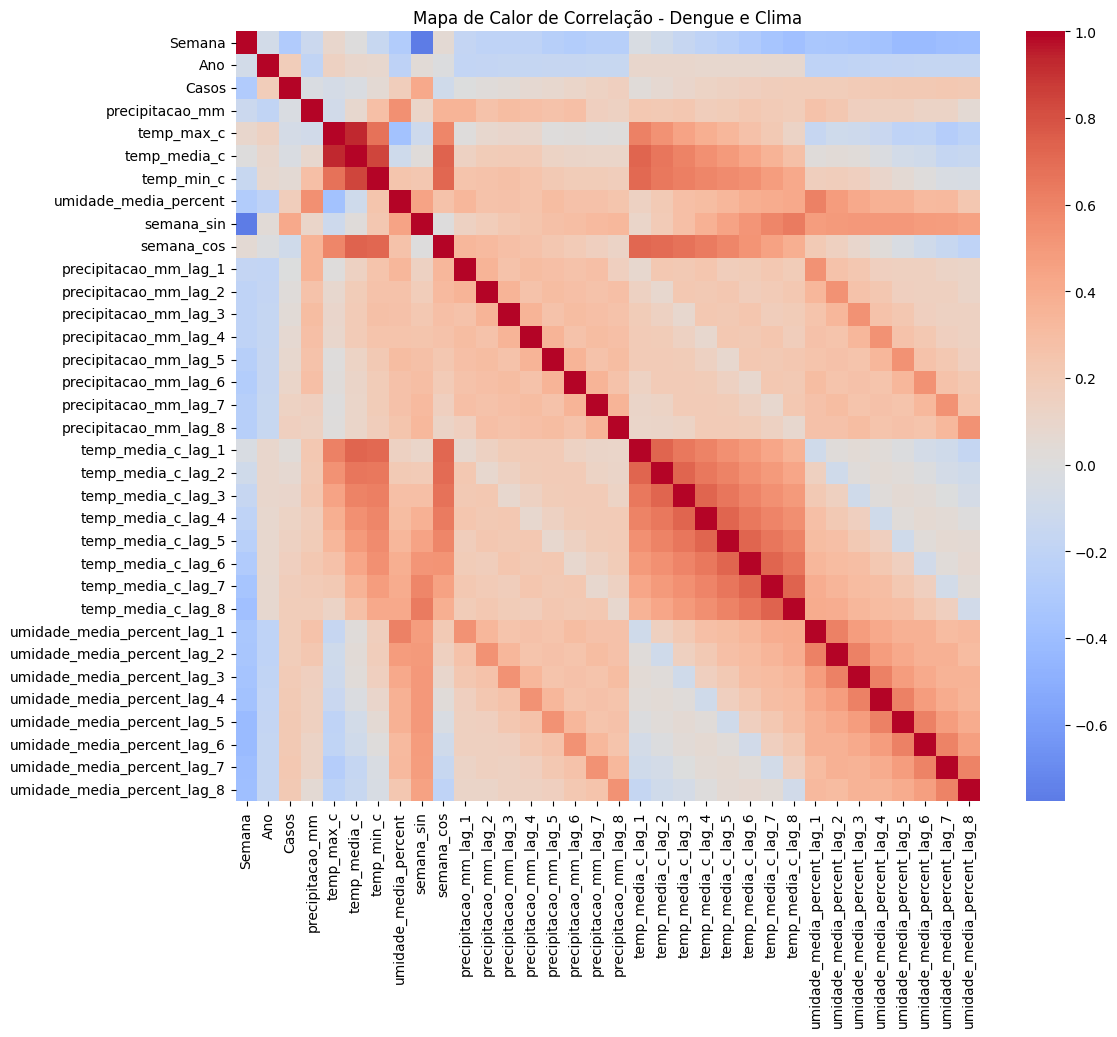

In [44]:
plt.figure(figsize=(12, 10))

# Plotando o heatmap
sns.heatmap(correlacao,
            annot=False,    # Se True, escreve o número (pode poluir se tiver muitas vars)
            cmap='coolwarm', # Azul (negativo) para Vermelho (positivo)
            center=0)       # Garante que o 0 seja branco/neutro

plt.title("Mapa de Calor de Correlação - Dengue e Clima")
plt.show()

/tmp/ipykernel_1493/1985005878.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr_alvo.values, y=corr_alvo.index, palette='viridis')


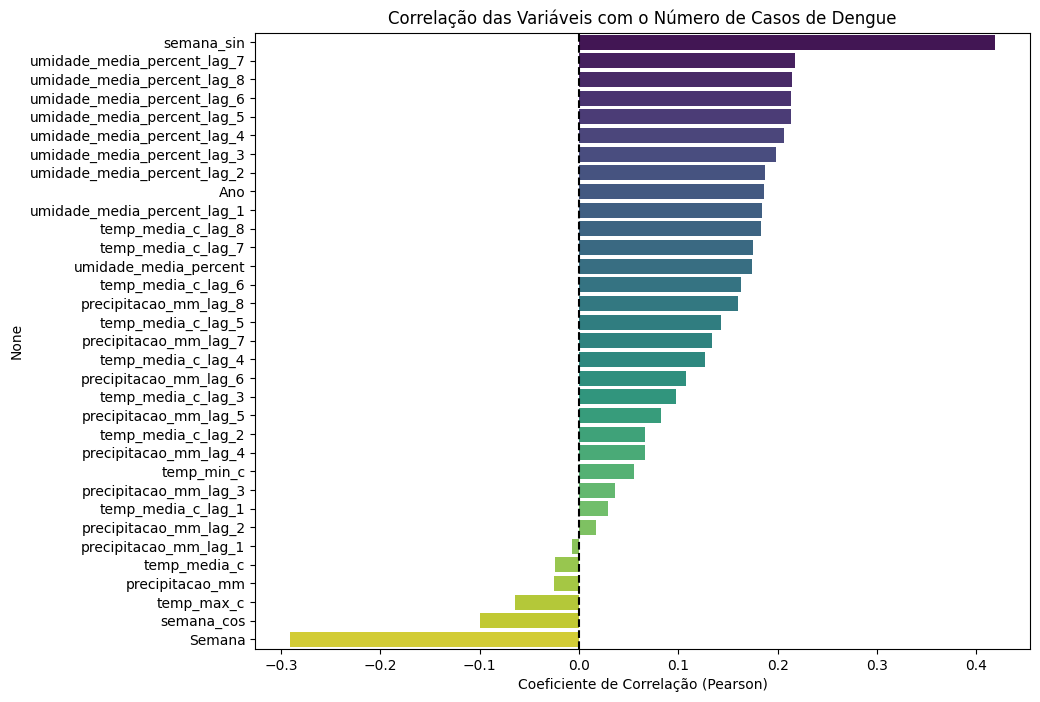

In [45]:
# Filtrar apenas a correlação com a coluna 'Casos' e ordenar
corr_alvo = correlacao['Casos'].sort_values(ascending=False)

# Remover a própria coluna 'Casos' (que sempre será 1.0)
corr_alvo = corr_alvo.drop('Casos')

# Plotar gráfico de barras
plt.figure(figsize=(10, 8))
sns.barplot(x=corr_alvo.values, y=corr_alvo.index, palette='viridis')

plt.title("Correlação das Variáveis com o Número de Casos de Dengue")
plt.xlabel("Coeficiente de Correlação (Pearson)")
plt.axvline(x=0, color='black', linestyle='--') # Linha do zero
plt.show()

/tmp/ipykernel_1493/2966830172.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Casos_lag_1'] = df_final['Casos'].shift(1) # Casos da semana passada
/tmp/ipykernel_1493/2966830172.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Casos_lag_2'] = df_final['Casos'].shift(2) # Casos de 2 semanas atrás
/tmp/ipykernel_1493/2966830172.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

S

NOVO Erro Médio Absoluto (MAE): 12.59 casos
NOVO RMSE: 26.26


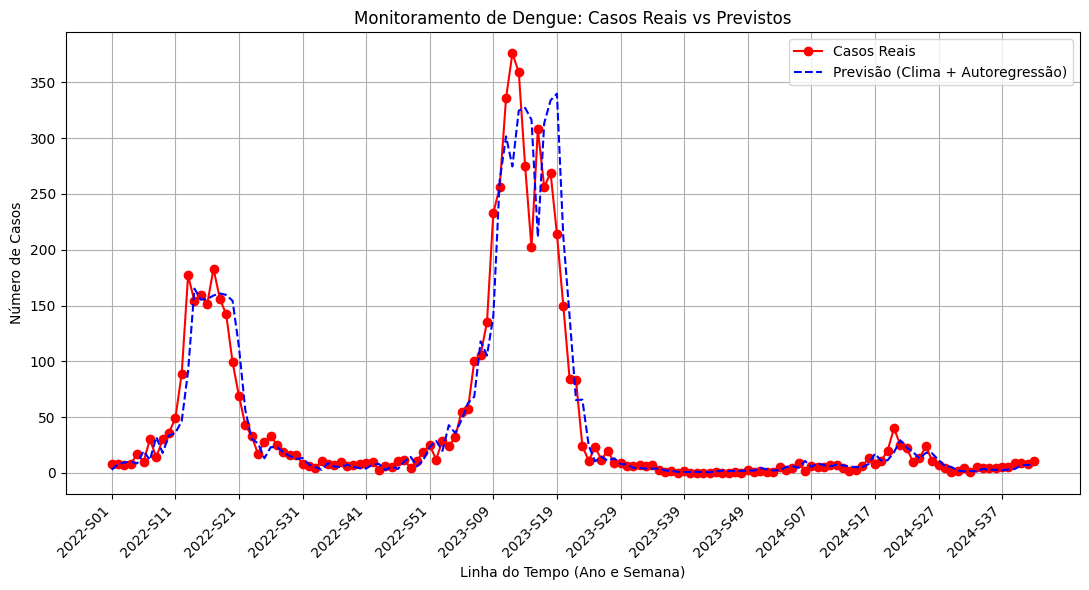

In [46]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# 1. Criar Lags para a variável alvo (Histórico recente de Casos)
df_final['Casos_lag_1'] = df_final['Casos'].shift(1) # Casos da semana passada
df_final['Casos_lag_2'] = df_final['Casos'].shift(2) # Casos de 2 semanas atrás
df_final['Casos_lag_3'] = df_final['Casos'].shift(3) # Casos de 3 semanas atrás

# 2. Remover as linhas vazias (NaN) geradas pelo shift no começo da tabela
df_final = df_final.dropna()

# 3. Atualizar a lista de variáveis que o modelo vai olhar (Features)
features_selecionadas = [
    'Ano',
    'semana_sin',
    'semana_cos',
    'umidade_media_percent_lag_6',
    'umidade_media_percent_lag_7',
    'umidade_media_percent_lag_8',
    'temp_media_c_lag_6',
    'temp_media_c_lag_7',
    'temp_media_c_lag_8',
    'precipitacao_mm_lag_6',
    'precipitacao_mm_lag_7',
    'precipitacao_mm_lag_8',
    # --- AS NOVAS VARIÁVEIS AQUI ---
    'Casos_lag_1',
    'Casos_lag_2',
    'Casos_lag_3'
]
alvo = 'Casos'

# 4. Refazer a divisão de Treino e Teste (Obrigatório após o dropna)
# Ajuste o 'ano_corte' se no seu projeto for diferente de 2023
ano_corte = 2022
df_treino = df_final[df_final['Ano'] < ano_corte]
df_teste = df_final[df_final['Ano'] >= ano_corte]

X_treino = df_treino[features_selecionadas]
y_treino = df_treino[alvo]

X_teste = df_teste[features_selecionadas]
y_teste = df_teste[alvo]

# 5. Criar e treinar o modelo (agora sem amarras para ele tentar prever picos altos)
modelo_rf_ar = RandomForestRegressor(n_estimators=200, random_state=42)
modelo_rf_ar.fit(X_treino, y_treino)

# 6. Fazer as previsões para o Teste
previsoes_rf_ar = modelo_rf_ar.predict(X_teste)

# 7. Avaliar as métricas (Vamos ver se sai da casa dos 42 casos de erro)
novo_mae = mean_absolute_error(y_teste, previsoes_rf_ar)
novo_rmse = root_mean_squared_error(y_teste, previsoes_rf_ar)

print(f"NOVO Erro Médio Absoluto (MAE): {novo_mae:.2f} casos")
print(f"NOVO RMSE: {novo_rmse:.2f}")

# 8. Plotar o novo Gráfico
plt.figure(figsize=(11, 6))

# Cria um texto com "Ano-Semana" para ficar bonito no eixo X (ex: "2023-S01")
eixo_x_formatado = df_teste['Ano'].astype(str) + "-S" + df_teste['Semana'].astype(str).str.zfill(2)

y_teste_plot = pd.to_numeric(y_teste)

plt.plot(eixo_x_formatado, y_teste_plot, label='Casos Reais', color='red', marker='o')
plt.plot(eixo_x_formatado, previsoes_rf_ar, label='Previsão (Clima + Autoregressão)', color='blue', linestyle='--')

plt.title(f'Monitoramento de Dengue: Casos Reais vs Previstos')
plt.xlabel('Linha do Tempo (Ano e Semana)')
plt.ylabel('Número de Casos')
plt.legend()
plt.grid(True)

# Gira os textos do eixo X para não ficarem amontoados
plt.xticks(rotation=45, ha='right')

# Mostra apenas 1 a cada 10 semanas no eixo X para não poluir visualmente
plt.xticks(eixo_x_formatado[::10])

plt.tight_layout()
plt.show()

In [47]:
# 1. Guardar o modelo preditivo
joblib.dump(modelo_rf_ar, '/content/drive/MyDrive/IC/modelo_dengue_rf.joblib')

# 2. Guardar a tabela final (apenas as colunas necessárias) para a plataforma carregar rápido
df_final.to_csv('/content/drive/MyDrive/IC/dados_preparados.csv', index=False)

print("Modelo e dados guardados com sucesso!")

Modelo e dados guardados com sucesso!
